In [40]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import numpy as np
from sklearn.model_selection import train_test_split

# Load data, preprocessing dan split

In [41]:
file_path = './Dataset/'
x, y =[], []
counter = 0
classes = os.listdir(file_path)
classes

['Broccoli', 'Carrot', 'Cucumber', 'Tomato']

In [42]:
for folder in classes:
    for img_path in os.listdir(f'{file_path}{folder}'):
        path = f'{file_path}{folder}/{img_path}'
        label = counter
        image = tf.keras.preprocessing.image.load_img(path, target_size=(64,64), color_mode='grayscale')
        image = tf.keras.preprocessing.image.img_to_array(image)
        x.append(image)
        y.append(label)
    counter+=1

x = np.array(x)
y = np.array(y)
x = x.astype('float32')/255.0

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=.2, random_state=88)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=88)

y_train = keras.utils.to_categorical(y_train)
y_val = keras.utils.to_categorical(y_val)
y_test = keras.utils.to_categorical(y_test)

In [43]:
print(x_train.shape)

(1600, 64, 64, 1)


# Buat model

In [44]:
model = keras.Sequential()
model.add(keras.layers.Conv2D(6, (5,5), strides=(1,1), activation='relu', input_shape=(64,64,1)))
model.add(keras.layers.MaxPooling2D((2,2)))
model.add(keras.layers.Conv2D(16, (5,5), strides=(1,1), activation='relu'))
model.add(keras.layers.MaxPooling2D((2,2)))

model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(32, activation='relu'))
model.add(keras.layers.Dense(4, activation='softmax'))

model.summary()

c:\Users\sovin\miniconda3\envs\ml\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 2704)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        86,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,264 (348.69 KB)

 Trainable params: 89,264 (348.69 KB)

 Non-trainable params: 0 (0.00 B)

# Compile dan train model

In [45]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=30, batch_size=32, validation_data=(x_val, y_val))

Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.3113 - loss: 1.3359 - val_accuracy: 0.4400 - val_loss: 1.1914
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5412 - loss: 1.0613 - val_accuracy: 0.5300 - val_loss: 1.1015
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6438 - loss: 0.8816 - val_accuracy: 0.6750 - val_loss: 0.7623
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7212 - loss: 0.6808 - val_accuracy: 0.7250 - val_loss: 0.6623
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7881 - loss: 0.5428 - val_accuracy: 0.7450 - val_loss: 0.5892
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - accuracy: 0.8244 - loss: 0.4563 - val_accuracy: 0.7700 - val_loss: 0.5092
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.8375 - loss: 0.4309 - val_accuracy: 0.8100 - val_loss: 0.4891
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.8744 - loss: 0.3535 - val_accuracy: 0.8450 - 

# Evaluasi di test set

In [46]:
model.evaluate(x_test, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8700 - loss: 0.4442 


[0.4442088305950165, 0.8700000047683716]

In [47]:
predictions = model.predict(x_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


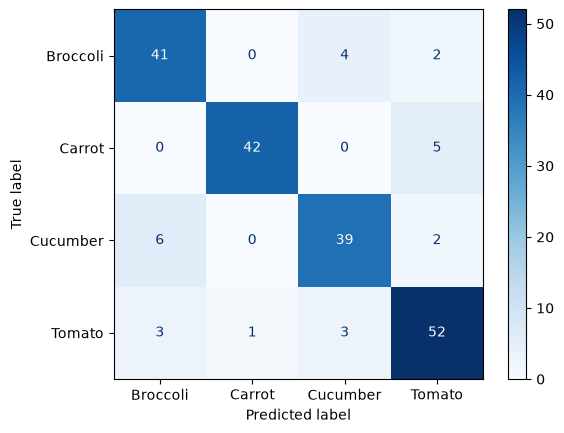

              precision    recall  f1-score   support

    Broccoli       0.82      0.87      0.85        47
      Carrot       0.98      0.89      0.93        47
    Cucumber       0.85      0.83      0.84        47
      Tomato       0.85      0.88      0.87        59

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



In [48]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues')
plt.show()

print(classification_report(y_true, y_pred, target_names=classes))

# Membandingkan aktual dan prediksi

In [49]:
for i in range(20):
    print(f'Actual: {classes[np.argmax(y_test[i])]} | Pred: {classes[np.argmax(predictions[i])]}')

Actual: Broccoli | Pred: Broccoli
Actual: Tomato | Pred: Tomato
Actual: Broccoli | Pred: Broccoli
Actual: Tomato | Pred: Tomato
Actual: Carrot | Pred: Carrot
Actual: Tomato | Pred: Tomato
Actual: Broccoli | Pred: Broccoli
Actual: Tomato | Pred: Tomato
Actual: Carrot | Pred: Carrot
Actual: Broccoli | Pred: Broccoli
Actual: Broccoli | Pred: Cucumber
Actual: Cucumber | Pred: Cucumber
Actual: Tomato | Pred: Tomato
Actual: Carrot | Pred: Carrot
Actual: Tomato | Pred: Tomato
Actual: Cucumber | Pred: Cucumber
Actual: Tomato | Pred: Cucumber
Actual: Carrot | Pred: Carrot
Actual: Cucumber | Pred: Cucumber
Actual: Cucumber | Pred: Cucumber


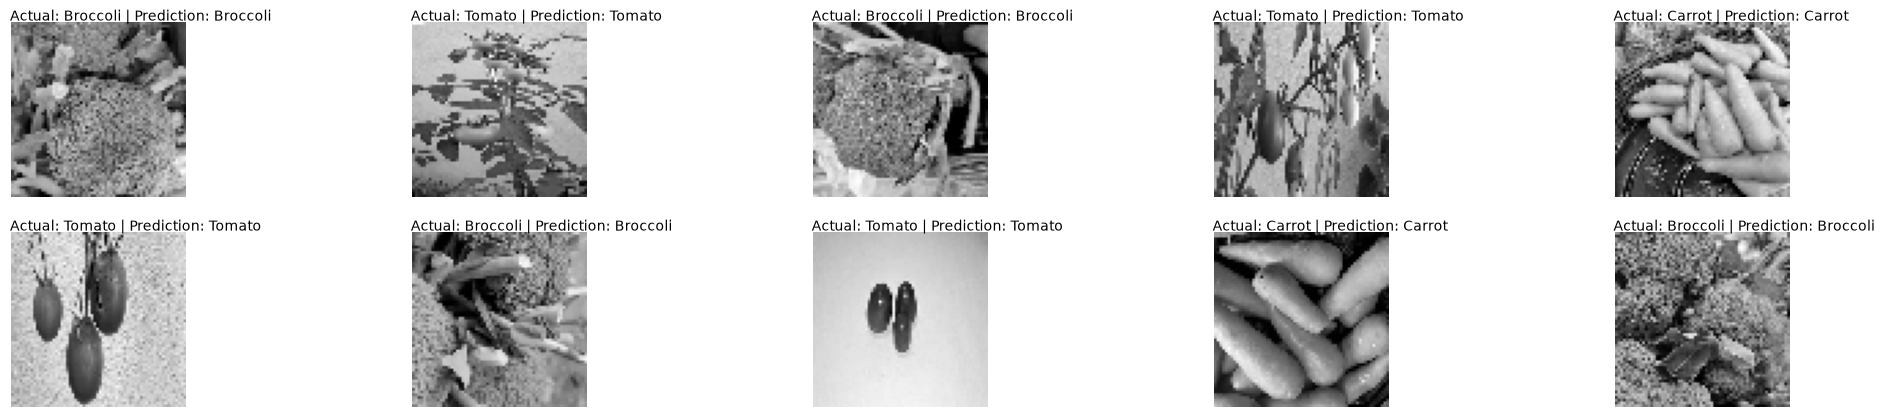

In [50]:
plt.figure(figsize=(25,5))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.text(-1, -1, f'Actual: {classes[np.argmax(y_test[i])]} | Prediction: {classes[np.argmax(predictions[i])]}')
    plt.axis(False)

    plt.subplot(2, 5, i+6)
    plt.imshow(x_test[i+5], cmap='gray')
    plt.text(-1, -1, f'Actual: {classes[np.argmax(y_test[i+5])]} | Prediction: {classes[np.argmax(predictions[i+5])]}')
    plt.axis(False)

# Training curve

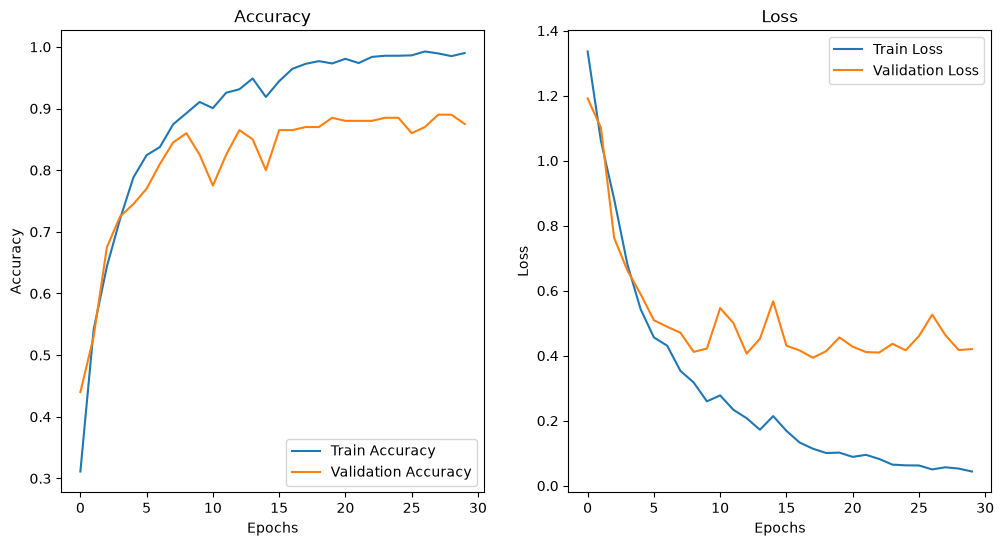

In [51]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()